# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Al Furqon
- NIM   : 241011400095
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 95

In [2]:
# Salin fungsi train_test_split dari materi di sini

def train_test_split(X, y, test_size=0.25, random_state=95):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = (round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

In [3]:
# Jawaban A1

# 1. Membaca dataset
df = pd.read_csv("Ads_Data.csv")

# Menampilkan 5 data pertama
display(df.head())

# Menampilkan jumlah baris data
print("Jumlah baris data:", len(df))

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40


In [4]:
# 2. Memisahkan fitur (X) dan target (y)
X = df[["BiayaIklan"]].to_numpy()
y = df["Penjualan"].to_numpy()

# Memeriksa bentuk data
print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (40, 1)
Shape y: (40,)


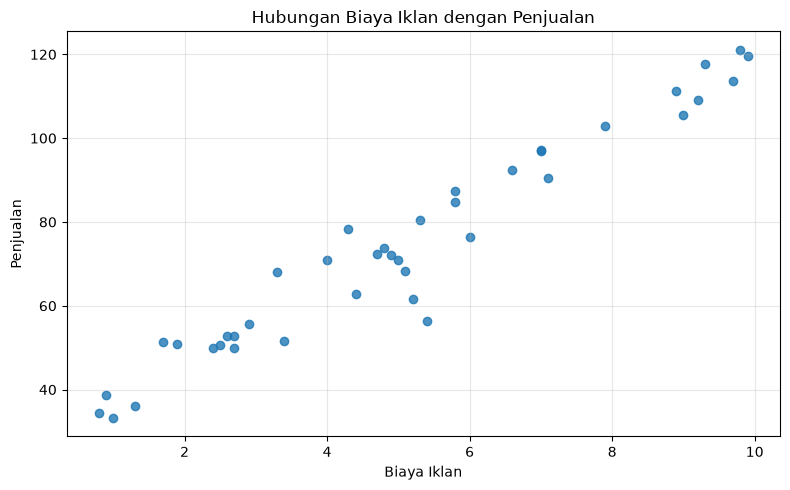

In [5]:
# 3. Membuat scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], y, alpha=0.8)

plt.title("Hubungan Biaya Iklan dengan Penjualan")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2

# Menentukan jumlah data training dan testing
n_samples = len(X)
n_test = int(np.ceil(n_samples * 0.2))

# Mengacak indeks data secara reproducible
rng = np.random.RandomState(RANDOM_STATE)
indices = rng.permutation(n_samples)

# Membagi indeks training dan testing
test_indices = indices[:n_test]
train_indices = indices[n_test:]

# Membagi X dan y
X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# Menampilkan shape setiap data
print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [7]:
# Jawaban A3

# Implementasi Linear Regression menggunakan Normal Equation
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)

        # Menambahkan kolom 1 untuk menghitung intercept
        X_bias = np.c_[np.ones((X.shape[0], 1)), X]

        # Menghitung parameter dengan Normal Equation
        theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.coef_ + self.intercept_


# Membuat dan melatih model menggunakan data training
model = LinearRegression()
model.fit(X_train, y_train)

# Mengambil nilai intercept dan koefisien
b = model.intercept_
m = model.coef_[0]

# Menampilkan hasil
print("Intercept (b):", round(b, 4))
print("Koefisien (m):", round(m, 4))
print(f"Persamaan regresi: ŷ = {b:.4f} + ({m:.4f})X")

Intercept (b): 27.8357
Koefisien (m): 9.198
Persamaan regresi: ŷ = 27.8357 + (9.1980)X


**Jawaban A3 (interpretasi):** 

Model Linear Regression dilatih menggunakan metode Normal Equation pada data training. Berdasarkan hasil perhitungan, nilai intercept (b) adalah **27.8357** dan koefisien regresi (m) adalah **9.198**. Dengan demikian, persamaan garis regresinya adalah ŷ = 27.8357 + (9.1980)X.

Nilai koefisien \(m\) menunjukkan perubahan prediksi penjualan untuk setiap kenaikan satu satuan biaya iklan. Jika satuan BiayaIklan pada dataset adalah juta rupiah dan nilai \(m\) positif, setiap kenaikan biaya iklan sebesar Rp1 juta diperkirakan meningkatkan penjualan sebesar \(m\) satuan, dengan asumsi hubungan linear. Sebaliknya, jika \(m\) negatif, prediksi penjualan cenderung menurun sebesar nilai absolut \(m\) satuan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4

# Implementasi metrik evaluasi regresi menggunakan NumPy

def mae_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return np.mean(np.abs(y_true - y_pred))


def mse_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return np.mean((y_true - y_pred) ** 2)


def rmse_numpy(y_true, y_pred):
    return np.sqrt(mse_numpy(y_true, y_pred))


def r2_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if ss_tot == 0:
        return np.nan

    return 1 - (ss_res / ss_tot)

In [9]:
# Prediksi data training dan testing
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Menghitung metrik pada data training
train_metrics = {
    "MAE": mae_numpy(y_train, y_train_pred),
    "MSE": mse_numpy(y_train, y_train_pred),
    "RMSE": rmse_numpy(y_train, y_train_pred),
    "R2": r2_numpy(y_train, y_train_pred)
}

# Menghitung metrik pada data testing
test_metrics = {
    "MAE": mae_numpy(y_test, y_test_pred),
    "MSE": mse_numpy(y_test, y_test_pred),
    "RMSE": rmse_numpy(y_test, y_test_pred),
    "R2": r2_numpy(y_test, y_test_pred)
}

# Menampilkan hasil dalam satu tabel
results = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Testing"]
)

display(results.round(4))

,MAE,MSE,RMSE,R2
Training,4.5004,38.1144,6.1737,0.9422
Testing,4.3484,27.9564,5.2874,0.9328


**Jawaban A4 (analisis):** 

Berdasarkan hasil evaluasi, model regresi linear memiliki nilai RMSE sebesar **6,1737** pada data training dan **5,2874** pada data testing. Hal ini menunjukkan bahwa kesalahan prediksi berdasarkan RMSE pada data testing lebih kecil dibandingkan data training.

Nilai R² pada data training adalah **0,9422**, sedangkan pada data testing adalah **0,9328**. Artinya, model mampu menjelaskan sekitar 94,22% variasi penjualan pada data training dan 93,28% pada data testing. Karena nilai R² pada kedua data relatif tinggi dan perbedaannya kecil, model dapat dikatakan **cukup baik** dalam memprediksi penjualan serta memiliki kemampuan generalisasi yang cukup baik. Namun, penilaian akhir juga perlu mempertimbangkan skala penjualan dan pengujian pada data lain.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

In [10]:
# Jawaban A5

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        n_samples, n_features = X.shape

        # Inisialisasi parameter
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history_ = []

        for i in range(self.n_iterations):
            # Prediksi menggunakan parameter saat ini
            y_pred = X @ self.coef_ + self.intercept_

            # Menghitung Mean Squared Error (MSE)
            errors = y_pred - y
            loss = np.mean(errors ** 2)
            self.loss_history_.append(loss)

            # Menghentikan proses jika model sudah divergen
            if not np.isfinite(loss):
                print(
                    f"Learning rate {self.learning_rate}: "
                    f"divergen pada iterasi ke-{i + 1}"
                )
                break

            # Menghitung gradien
            dw = (2 / n_samples) * (X.T @ errors)
            db = 2 * np.mean(errors)

            # Memperbarui parameter
            self.coef_ -= self.learning_rate * dw
            self.intercept_ -= self.learning_rate * db

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return X @ self.coef_ + self.intercept_

In [11]:
# Learning rate yang akan diuji
learning_rates = [0.001, 0.02, 0.1]

# Menyimpan setiap model Gradient Descent
gd_models = {}

# Menyimpan hasil perbandingan
rows = [{
    "Model": "Normal Equation",
    "Learning Rate": "-",
    "Intercept (b)": model.intercept_,
    "Koefisien (m)": model.coef_[0],
    "MSE terakhir": mse_numpy(y_train, model.predict(X_train)),
    "Selisih b vs NE": 0.0,
    "Selisih m vs NE": 0.0
}]

for lr in learning_rates:
    gd_model = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )

    gd_model.fit(X_train, y_train)
    gd_models[lr] = gd_model

    # Parameter akhir
    b_gd = gd_model.intercept_
    m_gd = gd_model.coef_[0]

    # MSE terakhir dari riwayat training
    final_loss = gd_model.loss_history_[-1]

    rows.append({
        "Model": "Gradient Descent",
        "Learning Rate": lr,
        "Intercept (b)": b_gd,
        "Koefisien (m)": m_gd,
        "MSE terakhir": final_loss,
        "Selisih b vs NE": b_gd - model.intercept_,
        "Selisih m vs NE": m_gd - model.coef_[0]
    })

# Tampilkan perbandingan
comparison_df = pd.DataFrame(rows)

display(comparison_df.round(6))

Learning rate 0.1: divergen pada iterasi ke-191


d:\Development\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


,Model,Learning Rate,Intercept (b),Koefisien (m),MSE terakhir,Selisih b vs NE,Selisih m vs NE
0,Normal Equation,-,2.783567e+01,9.197992e+00,38.114420,0.000000e+00,0.000000e+00
1,Gradient Descent,0.001,2.440431e+01,9.713440e+00,40.548123,-3.431361e+00,5.154480e-01
2,Gradient Descent,0.02,2.783567e+01,9.197992e+00,38.114420,-0.000000e+00,0.000000e+00
3,Gradient Descent,0.1,-6.533647e+151,-4.349475e+152,inf,-6.533647e+151,-4.349475e+152


d:\Development\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


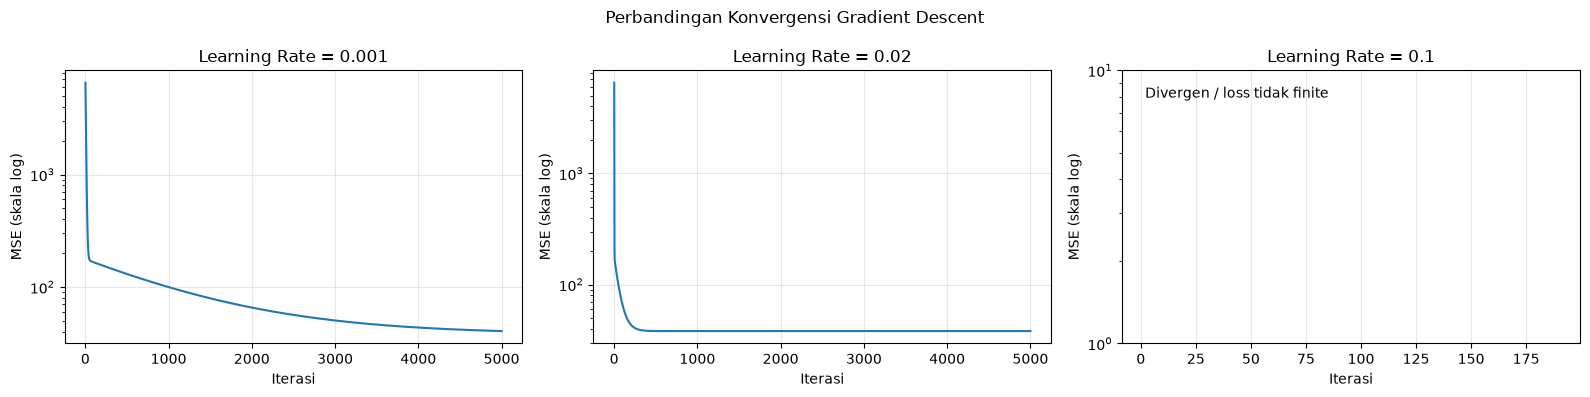

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, lr in zip(axes, learning_rates):
    gd_model = gd_models[lr]

    losses = np.asarray(gd_model.loss_history_, dtype=float)
    iterations = np.arange(1, len(losses) + 1)

    # Hanya menampilkan loss positif dan finite
    # agar dapat digambar pada skala logaritmik
    valid = np.isfinite(losses) & (losses > 0)

    ax.plot(iterations[valid], losses[valid])
    ax.set_yscale("log")
    ax.set_title(f"Learning Rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("MSE (skala log)")
    ax.grid(True, alpha=0.3)

    if len(losses) < gd_model.n_iterations:
        ax.text(
            0.05, 0.90,
            "Divergen / loss tidak finite",
            transform=ax.transAxes
        )

fig.suptitle("Perbandingan Konvergensi Gradient Descent")
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):** 

Eksperimen Gradient Descent dilakukan menggunakan learning rate 0.001, 0.02, dan 0.1 dengan batas maksimum 5.000 iterasi. Pada learning rate 0.001, loss menurun lebih lambat karena perubahan parameter pada setiap iterasi relatif kecil. Pada learning rate 0.02, loss menurun dan mencapai kondisi stabil sehingga nilai intercept dan koefisien mendekati hasil Normal Equation. Sementara itu, learning rate 0.1 diperkirakan mengalami divergensi karena ukuran langkah pembaruan parameter terlalu besar.

Divergensi dapat menyebabkan munculnya RuntimeWarning: overflow, inf, atau NaN. Hal ini terjadi ketika nilai parameter dan kesalahan prediksi meningkat sangat besar sehingga perhitungan numerik tidak lagi dapat dilakukan secara valid. Dengan demikian, pemilihan learning rate yang tepat sangat penting untuk memperoleh proses training yang cepat sekaligus stabil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

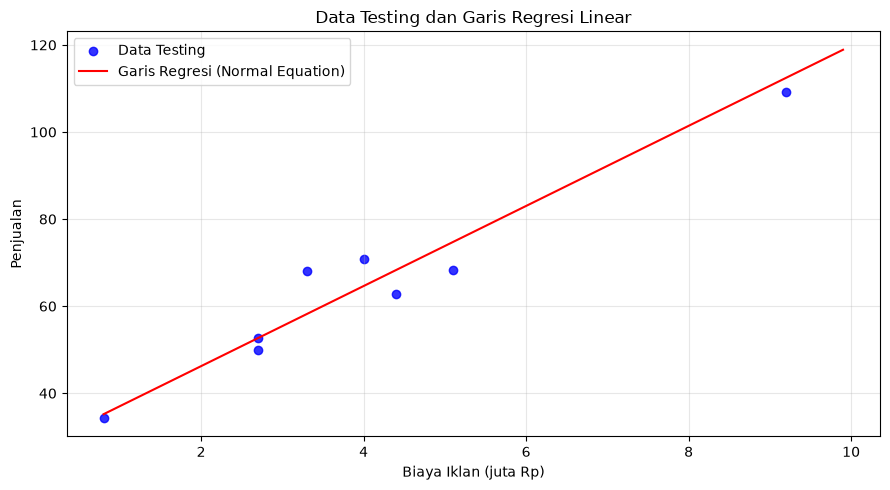

In [13]:
# Jawaban A6

# 1. Membuat garis regresi berdasarkan model Normal Equation (Soal A3)
X_line = np.linspace(
    X[:, 0].min(),
    X[:, 0].max(),
    200
).reshape(-1, 1)

y_line = model.predict(X_line)

# Visualisasi data testing dan garis regresi
plt.figure(figsize=(9, 5))

plt.scatter(
    X_test[:, 0],
    y_test,
    color="blue",
    label="Data Testing",
    alpha=0.8
)

plt.plot(
    X_line[:, 0],
    y_line,
    color="red",
    label="Garis Regresi (Normal Equation)"
)

plt.title("Data Testing dan Garis Regresi Linear")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Biaya iklan yang akan diprediksi (dalam juta rupiah)
biaya_iklan_baru = np.array([4.5, 7.0, 12.0]).reshape(-1, 1)

# Melakukan prediksi menggunakan model Normal Equation
prediksi_penjualan = model.predict(biaya_iklan_baru)

# Menampilkan hasil prediksi dalam tabel
hasil_prediksi = pd.DataFrame({
    "BiayaIklan (juta Rp)": biaya_iklan_baru.ravel(),
    "Prediksi Penjualan": prediksi_penjualan
})

display(hasil_prediksi.round(4))

,BiayaIklan (juta Rp),Prediksi Penjualan
0,4.5,69.2266
1,7.0,92.2216
2,12.0,138.2116


**Jawaban A6 (analisis):** 

Berdasarkan grafik scatter plot dan garis regresi, model Linear Regression digunakan untuk menggambarkan hubungan antara biaya iklan dan penjualan. Model kemudian digunakan untuk memprediksi penjualan pada biaya iklan Rp4,5 juta, Rp7 juta, dan Rp12 juta.

Prediksi untuk biaya iklan Rp4,5 juta dan Rp7 juta lebih dapat dipercaya karena masih berada dalam rentang data yang diamati. Sementara itu, prediksi untuk Rp12 juta merupakan ekstrapolasi karena melebihi biaya iklan maksimum dalam dataset, yaitu Rp9,9 juta. Oleh karena itu, hasil prediksi Rp12 juta perlu digunakan dengan hati-hati karena asumsi hubungan linear belum tentu berlaku di luar rentang data yang tersedia. Untuk meningkatkan kepercayaan terhadap prediksi tersebut, diperlukan data tambahan dengan biaya iklan yang lebih tinggi.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

In [15]:
# Jawaban B1

# 1. Membaca dataset
df_email = pd.read_csv("Email_Data.csv")

# Menampilkan 5 data pertama
display(df_email.head())

# Menghitung jumlah email berdasarkan kelas
jumlah_email = df_email["Spam"].value_counts().sort_index()

print("Jumlah email Bukan Spam:", jumlah_email.get(0, 0))
print("Jumlah email Spam:", jumlah_email.get(1, 0))
print("Total email:", len(df_email))

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email Bukan Spam: 35
Jumlah email Spam: 25
Total email: 60


In [16]:
# 2. Memisahkan fitur dan target
X = df_email[["JumlahLink", "KataPromo"]].to_numpy()
y = df_email["Spam"].to_numpy()

# Memeriksa bentuk data
print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (60, 2)
Shape y: (60,)


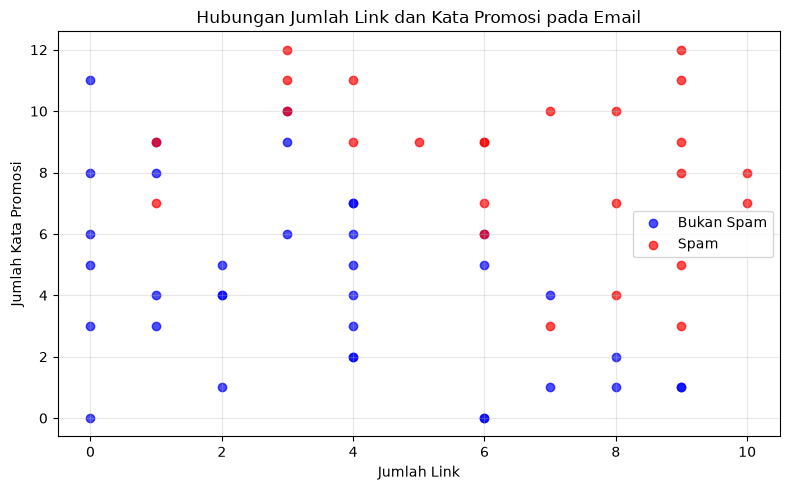

In [17]:
# 3. Memisahkan data berdasarkan kelas
spam = df_email[df_email["Spam"] == 1]
bukan_spam = df_email[df_email["Spam"] == 0]

# Membuat scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    bukan_spam["JumlahLink"],
    bukan_spam["KataPromo"],
    color="blue",
    label="Bukan Spam",
    alpha=0.7
)

plt.scatter(
    spam["JumlahLink"],
    spam["KataPromo"],
    color="red",
    label="Spam",
    alpha=0.7
)

plt.title("Hubungan Jumlah Link dan Kata Promosi pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promosi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [18]:
# Jawaban B2

# Menyiapkan fitur dan target email
X_email = df_email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = df_email["Spam"].to_numpy(dtype=int)

# Membagi data menggunakan NumPy
n_samples = len(X_email)
n_test = int(np.ceil(n_samples * 0.25))

rng = np.random.RandomState(RANDOM_STATE)
indices = rng.permutation(n_samples)

test_indices = indices[:n_test]
train_indices = indices[n_test:]

X_train, X_test = X_email[train_indices], X_email[test_indices]
y_train, y_test = y_email[train_indices], y_email[test_indices]

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (45, 2)
Shape X_test : (15, 2)
Shape y_train: (45,)
Shape y_test : (15,)


In [19]:
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def sigmoid(self, z):
        # Membatasi nilai z untuk menghindari overflow numerik
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        n_samples, n_features = X.shape

        # Inisialisasi parameter
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history_ = []

        for _ in range(self.n_iterations):
            # Menghitung probabilitas prediksi
            z = X @ self.coef_ + self.intercept_
            y_pred = self.sigmoid(z)

            # Menghitung log loss
            p = np.clip(y_pred, 1e-15, 1 - 1e-15)
            loss = -np.mean(
                y * np.log(p) +
                (1 - y) * np.log(1 - p)
            )
            self.loss_history_.append(loss)

            # Menghitung gradien
            errors = y_pred - y
            dw = (X.T @ errors) / n_samples
            db = np.mean(errors)

            # Memperbarui parameter
            self.coef_ -= self.learning_rate * dw
            self.intercept_ -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return self.sigmoid(X @ self.coef_ + self.intercept_)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)


# Melatih model
log_model = LogisticRegression(
    learning_rate=0.1,
    n_iterations=10000
)

log_model.fit(X_train, y_train)

print("Intercept (b):", round(log_model.intercept_, 6))
print("Koefisien m1 (JumlahLink):", round(log_model.coef_[0], 6))
print("Koefisien m2 (KataPromo):", round(log_model.coef_[1], 6))

print("\nPersamaan probabilitas:")
print(
    f"P(Spam) = σ({log_model.intercept_:.6f} "
    f"+ ({log_model.coef_[0]:.6f} × JumlahLink) "
    f"+ ({log_model.coef_[1]:.6f} × KataPromo))"
)

Intercept (b): -15.006311
Koefisien m1 (JumlahLink): 1.368714
Koefisien m2 (KataPromo): 1.118385

Persamaan probabilitas:
P(Spam) = σ(-15.006311 + (1.368714 × JumlahLink) + (1.118385 × KataPromo))


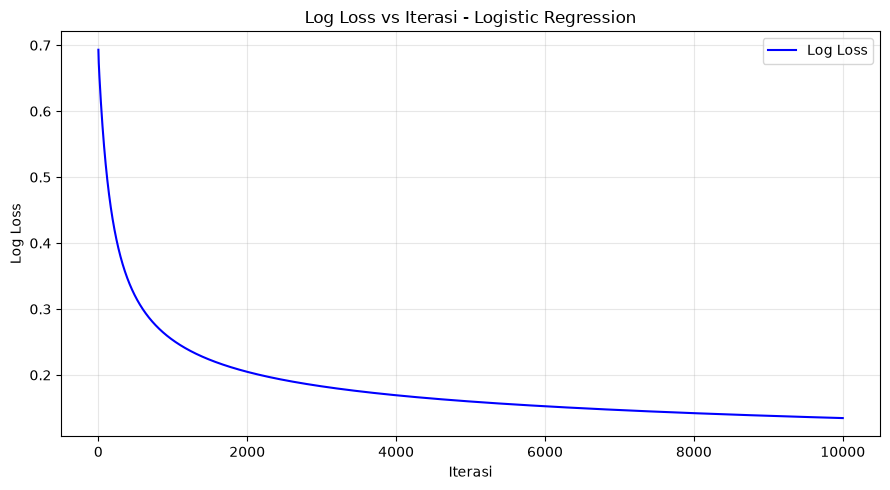

Log loss awal : 0.693147
Log loss akhir: 0.134641


In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(log_model.loss_history_) + 1),
    log_model.loss_history_,
    label="Log Loss",
    color="blue"
)

plt.title("Log Loss vs Iterasi - Logistic Regression")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Log loss awal :", round(log_model.loss_history_[0], 6))
print("Log loss akhir:", round(log_model.loss_history_[-1], 6))

4. Apakah loss sudah turun dan stabil?
Berdasarkan grafik, log loss mengalami penurunan dari 0,693147 pada awal training menjadi 0,134641 setelah 10.000 iterasi. Penurunan ini menunjukkan bahwa model Logistic Regression semakin baik dalam mempelajari hubungan antara jumlah link, kata promosi, dan label spam. Pada awal iterasi, loss turun dengan cepat, kemudian penurunannya melambat dan cenderung stabil. Hal ini menunjukkan bahwa proses training mendekati konvergensi. Namun, evaluasi pada data testing tetap diperlukan untuk mengetahui kemampuan model dalam memprediksi email baru.

**Jawaban B2 (analisis):** 

Data dibagi menjadi 45 data training dan 15 data testing menggunakan test_size=0.25 dan RANDOM_STATE sesuai NIM (95). Model Logistic Regression kemudian dilatih menggunakan Gradient Descent dengan learning rate 0,1 dan 10.000 iterasi.

Berdasarkan grafik log loss, nilai loss mengalami penurunan dari awal training dan kemudian cenderung stabil. Hal ini menunjukkan bahwa model semakin baik dalam mempelajari hubungan antara jumlah link, kata promosi, dan label spam. Ketika loss mulai stabil, perubahan parameter pada setiap iterasi menjadi semakin kecil sehingga proses training mendekati konvergensi.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [21]:
# Jawaban B3

# Implementasi metrik klasifikasi menggunakan NumPy

def accuracy_score_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    return np.mean(y_true == y_pred)


def confusion_matrix_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    # Label 0 = Bukan Spam, label 1 = Spam
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    # Urutan baris = label aktual, kolom = prediksi
    return np.array([
        [tn, fp],
        [fn, tp]
    ])


def precision_numpy(y_true, y_pred):
    cm = confusion_matrix_numpy(y_true, y_pred)
    tn, fp = cm[0]
    fn, tp = cm[1]

    denominator = tp + fp
    return tp / denominator if denominator != 0 else 0.0


def recall_numpy(y_true, y_pred):
    cm = confusion_matrix_numpy(y_true, y_pred)
    fn, tp = cm[1]

    denominator = tp + fn
    return tp / denominator if denominator != 0 else 0.0


def f1_numpy(y_true, y_pred):
    precision = precision_numpy(y_true, y_pred)
    recall = recall_numpy(y_true, y_pred)

    denominator = precision + recall
    return (
        2 * precision * recall / denominator
        if denominator != 0 else 0.0
    )

In [22]:
# Prediksi label pada data testing
y_test_pred = log_model.predict(X_test)

# Menghitung metrik evaluasi
accuracy = accuracy_score_numpy(y_test, y_test_pred)
cm = confusion_matrix_numpy(y_test, y_test_pred)
precision = precision_numpy(y_test, y_test_pred)
recall = recall_numpy(y_test, y_test_pred)
f1 = f1_numpy(y_test, y_test_pred)

# Menampilkan confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["Aktual Bukan Spam", "Aktual Spam"],
    columns=["Prediksi Bukan Spam", "Prediksi Spam"]
)

print("Confusion Matrix:")
display(cm_df)

# Menampilkan semua metrik dalam satu tabel
metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Nilai": [accuracy, precision, recall, f1]
})

display(metrics_df.round(4))

Confusion Matrix:


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,8,0
Aktual Spam,3,4


,Metrik,Nilai
0,Accuracy,0.8000
1,Precision,1.0000
2,Recall,0.5714
3,F1-score,0.7273


**Jawaban B3 (analisis):** 

Evaluasi model dilakukan menggunakan data testing dengan menghitung accuracy, confusion matrix, precision, recall, dan F1-score. Accuracy menunjukkan persentase prediksi yang benar, precision mengukur ketepatan prediksi spam, recall mengukur kemampuan model menemukan email spam, sedangkan F1-score menyeimbangkan precision dan recall.

FP (*False Positive*) adalah email bukan spam yang salah diklasifikasikan sebagai spam. Kesalahan ini dapat menyebabkan email penting masuk ke folder spam dan terlewat oleh pengguna. Sementara itu, FN (*False Negative*) adalah email spam yang salah diklasifikasikan sebagai bukan spam sehingga tetap masuk ke kotak masuk utama.

Menurut saya, FP dapat lebih merugikan dalam penggunaan email sehari-hari karena pengguna berisiko melewatkan email penting. Namun, FN dapat lebih berbahaya jika email spam mengandung phishing atau tautan berbahaya. Oleh karena itu, filter spam perlu memiliki precision dan recall yang baik agar dapat mengurangi kedua jenis kesalahan tersebut.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

In [23]:
# Jawaban B4

# Mengambil parameter model Logistic Regression dari Soal B2
b = log_model.intercept_
m1, m2 = log_model.coef_

print(f"Intercept (b): {b:.6f}")
print(f"Koefisien m1 (JumlahLink): {m1:.6f}")
print(f"Koefisien m2 (KataPromo): {m2:.6f}")

print("\nPersamaan decision boundary:")
if not np.isclose(m2, 0):
    print(f"KataPromo = -({b:.6f} + ({m1:.6f}) * JumlahLink) / ({m2:.6f})")
else:
    print("Koefisien KataPromo mendekati nol, sehingga boundary perlu ditulis dalam bentuk lain.")
    if not np.isclose(m1, 0):
        print(f"JumlahLink = {-b / m1:.6f}")
    else:
        print("Kedua koefisien mendekati nol; boundary tidak dapat ditentukan dengan persamaan garis biasa.")

Intercept (b): -15.006311
Koefisien m1 (JumlahLink): 1.368714
Koefisien m2 (KataPromo): 1.118385

Persamaan decision boundary:
KataPromo = -(-15.006311 + (1.368714) * JumlahLink) / (1.118385)


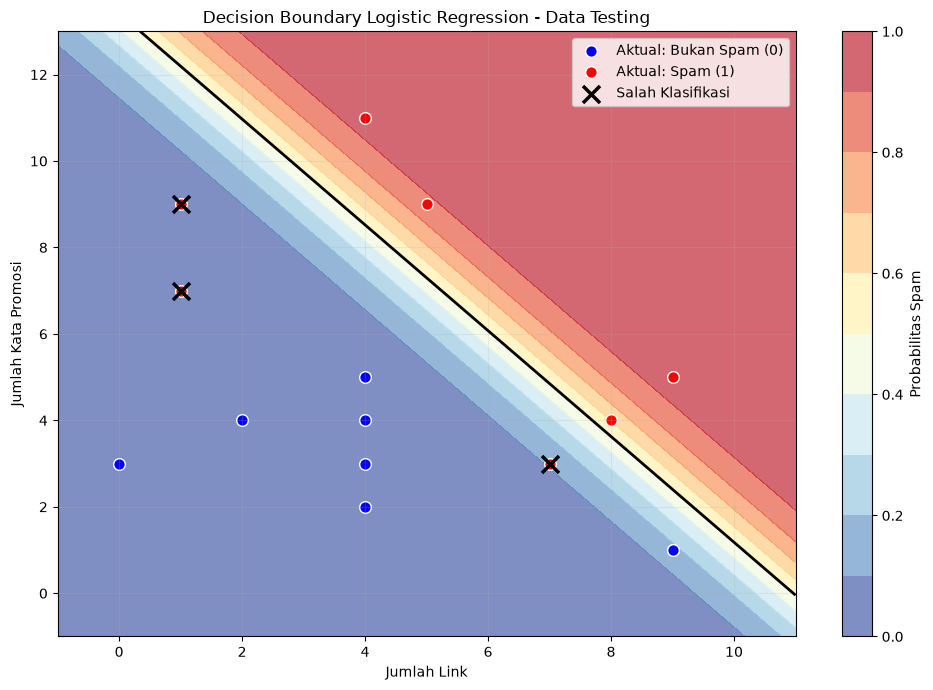

In [24]:
# Probabilitas dan prediksi pada data testing
y_test_prob = log_model.predict_proba(X_test)
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Membuat grid untuk background probabilitas
x1_min = df_email["JumlahLink"].min() - 1
x1_max = df_email["JumlahLink"].max() + 1
x2_min = df_email["KataPromo"].min() - 1
x2_max = df_email["KataPromo"].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 300),
    np.linspace(x2_min, x2_max, 300)
)

# Menghitung probabilitas spam di setiap titik grid
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_model.predict_proba(grid).reshape(xx1.shape)

# Mask untuk memisahkan email aktual spam dan bukan spam
actual_spam = y_test == 1
actual_not_spam = y_test == 0
misclassified = y_test != y_test_pred

plt.figure(figsize=(10, 7))

# Background probabilitas
contour = plt.contourf(
    xx1, xx2, prob_grid,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu_r",
    alpha=0.65
)

plt.colorbar(contour, label="Probabilitas Spam")

# Decision boundary: probabilitas = 0.5
plt.contour(
    xx1, xx2, prob_grid,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Titik data testing berdasarkan kelas aktual
plt.scatter(
    X_test[actual_not_spam, 0],
    X_test[actual_not_spam, 1],
    color="blue",
    edgecolors="white",
    label="Aktual: Bukan Spam (0)",
    s=70
)

plt.scatter(
    X_test[actual_spam, 0],
    X_test[actual_spam, 1],
    color="red",
    edgecolors="white",
    label="Aktual: Spam (1)",
    s=70
)

# Menandai prediksi yang salah dengan tanda silang hitam
plt.scatter(
    X_test[misclassified, 0],
    X_test[misclassified, 1],
    marker="x",
    color="black",
    linewidths=2.5,
    s=150,
    label="Salah Klasifikasi",
    zorder=5
)

plt.title("Decision Boundary Logistic Regression - Data Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promosi")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [25]:
# Membuat tabel email testing yang salah diklasifikasikan
misclassified_df = pd.DataFrame({
    "Index Dataset": test_indices[misclassified],
    "JumlahLink": X_test[misclassified, 0],
    "KataPromo": X_test[misclassified, 1],
    "Spam Aktual": y_test[misclassified],
    "Prediksi": y_test_pred[misclassified],
    "Probabilitas Spam": y_test_prob[misclassified]
})

print("Jumlah email yang salah diklasifikasikan:", misclassified.sum())

display(misclassified_df.round(4))

Jumlah email yang salah diklasifikasikan: 3


,Index Dataset,JumlahLink,KataPromo,Spam Aktual,Prediksi,Probabilitas Spam
0,9,1.0,9.0,1,0,0.0273
1,21,1.0,7.0,1,0,0.0030
2,10,7.0,3.0,1,0,0.1120


**Jawaban B4 (analisis):** 

Decision boundary pada Logistic Regression merupakan garis yang memisahkan wilayah prediksi spam dan bukan spam dengan batas probabilitas sebesar 0,5. Garis tersebut diperoleh dari persamaan \(b+m_1x_1+m_2x_2=0\), dengan \(x_1\) sebagai jumlah link dan \(x_2\) sebagai jumlah kata promosi.

Pada grafik, background menunjukkan probabilitas spam, sedangkan titik-titik menunjukkan data testing berdasarkan kelas aktual. Tanda silang hitam menandai email yang salah diklasifikasikan, yaitu ketika prediksi model berbeda dari label aktual.

Berdasarkan hasil pengujian, terdapat 3 email yang salah diklasifikasikan. Ketiga email tersebut merupakan False Negative (FN), yaitu email yang sebenarnya spam tetapi diprediksi sebagai bukan spam. Probabilitas spam ketiganya berada di bawah 0,5, sehingga model mengklasifikasikannya sebagai bukan spam. Kesalahan ini dapat terjadi karena model belum mampu mengenali pola spam secara tepat berdasarkan jumlah link dan kata promosi. Dengan demikian, decision boundary membantu menunjukkan bagian data testing yang masih salah diklasifikasikan oleh model.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [26]:
# Jawaban B5

# Probabilitas spam pada data testing
y_test_prob = log_model.predict_proba(X_test).ravel()

thresholds = [0.3, 0.5, 0.7]
results = []

for threshold in thresholds:
    # Membuat prediksi sesuai threshold
    y_pred_threshold = (y_test_prob >= threshold).astype(int)

    # Menghitung confusion matrix
    cm = confusion_matrix_numpy(y_test, y_pred_threshold)
    tn, fp = cm[0]
    fn, tp = cm[1]

    # Menghitung precision dan recall
    precision = precision_numpy(y_test, y_pred_threshold)
    recall = recall_numpy(y_test, y_pred_threshold)

    results.append({
        "Threshold": threshold,
        "Confusion Matrix": np.array2string(cm, separator=", "),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall
    })

# Menampilkan semua hasil dalam satu tabel
threshold_results = pd.DataFrame(results)
display(threshold_results.round(4))

,Threshold,Confusion Matrix,TN,FP,FN,TP,Precision,Recall
0,0.3,"[[8, 0],\n [3, 4]]",8,0,3,4,1.0,0.5714
1,0.5,"[[8, 0],\n [3, 4]]",8,0,3,4,1.0,0.5714
2,0.7,"[[8, 0],\n [4, 3]]",8,0,4,3,1.0,0.4286


**Jawaban B5 (analisis):** 

Berdasarkan hasil eksperimen, threshold 0,3 dan 0,5 menghasilkan precision sebesar 1,0000 dan recall sebesar 0,5714. Sementara itu, threshold 0,7 menghasilkan precision sebesar 1,0000 dan recall sebesar 0,4286. Pada data testing ini, semua threshold tidak menghasilkan False Positive, tetapi threshold 0,7 menyebabkan lebih banyak email spam tidak terdeteksi. Menurunkan threshold biasanya meningkatkan recall tetapi bisa menurunkan precision. Menaikkannya biasanya meningkatkan precision tetapi bisa menurunkan recall. Pada data di atas, threshold 0,3 dan 0,5 kebetulan menghasilkan metrik yang sama, sedangkan 0,7 menurunkan recall.

Berdasarkan analisis pada Soal B3, False Positive dapat merugikan pengguna karena email penting berisiko masuk ke folder spam. Namun, False Negative juga berbahaya jika email spam mengandung phishing atau tautan berbahaya. Oleh karena itu, saya memilih threshold 0,3 karena model lebih sensitif terhadap spam dan pada data testing ini tidak menambah False Positive dibandingkan threshold 0,5. Meskipun demikian, hasil ini perlu diuji pada data yang lebih banyak karena precision yang tinggi pada data testing belum menjamin risiko False Positive akan tetap rendah pada penggunaan nyata. 

Saya memilih threshold 0,3 karena ingin meningkatkan sensitivitas model dalam mendeteksi email spam. Pada data testing ini, threshold 0,3 dan 0,5 menghasilkan precision dan recall yang sama, sedangkan threshold 0,7 menghasilkan recall yang lebih rendah. Oleh karena itu, threshold 0,3 menjadi pilihan yang masuk akal, meskipun keunggulannya dibandingkan threshold 0,5 belum terlihat pada hasil pengujian ini.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [27]:
# Jawaban B6

# Threshold pilihan dari Soal B5
threshold_pilih = 0.3

# Data email baru
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

# Mengambil fitur untuk prediksi
X_email_baru = email_baru[
    ["JumlahLink", "KataPromo"]
].to_numpy(dtype=float)

# Menghitung probabilitas spam
probabilitas_spam = log_model.predict_proba(X_email_baru).ravel()

# Menentukan kelas berdasarkan threshold 0.3
prediksi_kelas = (probabilitas_spam >= threshold_pilih).astype(int)

# Membuat tabel hasil
hasil_b6 = email_baru.copy()
hasil_b6["Probabilitas Spam"] = probabilitas_spam
hasil_b6["Prediksi Kelas"] = prediksi_kelas
hasil_b6["Hasil Prediksi"] = np.where(
    prediksi_kelas == 1,
    "Spam",
    "Bukan Spam"
)

display(hasil_b6.round(6))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas,Hasil Prediksi
0,E1,1,2,0.000011,0,Bukan Spam
1,E2,5,6,0.189628,0,Bukan Spam
2,E3,9,10,0.999796,1,Spam
3,E4,2,11,0.508338,1,Spam


**Jawaban B6 (analisis):**

Berdasarkan hasil prediksi menggunakan Logistic Regression dengan threshold 0,3, email E1 diklasifikasikan sebagai bukan spam karena probabilitas spamnya sebesar 0,000011. Email E2 juga diklasifikasikan sebagai bukan spam dengan probabilitas 0,189628.

Email E3 diklasifikasikan sebagai spam karena memiliki probabilitas sebesar 0,999796, sedangkan E4 juga diklasifikasikan sebagai spam dengan probabilitas 0,508338. Kedua probabilitas tersebut lebih besar atau sama dengan threshold 0,3.

Dengan demikian, dari empat email yang diuji, model memprediksi **dua email sebagai spam (E3 dan E4)** dan **dua email sebagai bukan spam (E1 dan E2)**. Hasil ini merupakan prediksi model berdasarkan jumlah link dan kata promosi, bukan kepastian bahwa email tersebut benar-benar spam.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kelas suatu data, misalnya email spam atau bukan spam. Nama regression digunakan karena model menghitung kombinasi linear dari fitur, kemudian hasilnya diubah menjadi probabilitas. Fungsi sigmoid mengubah nilai tersebut menjadi probabilitas antara 0 dan 1. Probabilitas ini kemudian digunakan untuk menentukan kelas berdasarkan threshold, biasanya 0,5.

**Jawaban C2:** Normal Equation menghitung parameter regresi secara langsung menggunakan operasi matriks untuk mendapatkan solusi terbaik tanpa proses iterasi. Sementara itu, Gradient Descent mencari parameter secara bertahap dengan memperbaruinya berdasarkan gradien loss. Normal Equation cocok untuk dataset dengan jumlah fitur yang tidak terlalu banyak, sedangkan Gradient Descent lebih sesuai untuk dataset besar atau ketika perhitungan matriks secara langsung terlalu mahal. Gradient Descent juga memerlukan pemilihan learning rate yang tepat agar proses training berjalan stabil dan mencapai konvergensi.

**Jawaban C3:** Data testing digunakan untuk mengukur kemampuan model dalam memprediksi data yang tidak digunakan selama training. Jika hanya dievaluasi pada data training, hasilnya belum tentu menggambarkan kinerja model pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga kinerjanya pada data baru menjadi kurang baik. Oleh karena itu, hasil training dan testing perlu dibandingkan untuk menilai kemampuan generalisasi model.

**Jawaban C4:** Linear Regression menggunakan MSE untuk mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi numerik. Logistic Regression menghasilkan probabilitas untuk kelas, sehingga log loss digunakan untuk mengukur kesalahan probabilitas tersebut terhadap label sebenarnya. Log loss memberikan penalti besar ketika model membuat prediksi yang sangat yakin tetapi salah. Dengan demikian, MSE cocok untuk masalah regresi, sedangkan log loss cocok untuk klasifikasi probabilistik seperti spam dan bukan spam.

**Jawaban C5:** Hasil dapat berbeda karena setiap mahasiswa menggunakan random_state berdasarkan dua digit terakhir NIM, sehingga pembagian data training dan testing bisa berbeda. Perbedaan data training dapat menghasilkan koefisien, akurasi, dan metrik evaluasi yang berbeda. Pada Gradient Descent, hasil juga dapat dipengaruhi oleh learning rate, jumlah iterasi, dan nilai awal parameter. Oleh karena itu, penggunaan dataset dan algoritma yang sama tidak selalu menghasilkan angka yang sama jika proses eksperimennya berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [28]:
# Jawaban Bonus

from sklearn.linear_model import (
    LinearRegression as SKLinearRegression,
    LogisticRegression as SKLogisticRegression
)

# ==========================
# A. Dataset iklan
# ==========================
df_ads_bonus = pd.read_csv("Ads_Data.csv")

X_ads_bonus = df_ads_bonus[["BiayaIklan"]].to_numpy(dtype=float)
y_ads_bonus = df_ads_bonus["Penjualan"].to_numpy(dtype=float)

# Menggunakan pembagian yang sama seperti Soal A2
n_test_ads = int(np.ceil(len(X_ads_bonus) * 0.20))
indices_ads = np.random.RandomState(RANDOM_STATE).permutation(
    len(X_ads_bonus)
)

test_idx_ads = indices_ads[:n_test_ads]
train_idx_ads = indices_ads[n_test_ads:]

X_ads_train = X_ads_bonus[train_idx_ads]
X_ads_test = X_ads_bonus[test_idx_ads]
y_ads_train = y_ads_bonus[train_idx_ads]
y_ads_test = y_ads_bonus[test_idx_ads]


# ==========================
# B. Dataset email
# ==========================
df_email_bonus = pd.read_csv("Email_Data.csv")

X_email_bonus = df_email_bonus[
    ["JumlahLink", "KataPromo"]
].to_numpy(dtype=float)

y_email_bonus = df_email_bonus["Spam"].to_numpy(dtype=int)

# Menggunakan pembagian yang sama seperti Soal B2
n_test_email = int(np.ceil(len(X_email_bonus) * 0.25))
indices_email = np.random.RandomState(RANDOM_STATE).permutation(
    len(X_email_bonus)
)

test_idx_email = indices_email[:n_test_email]
train_idx_email = indices_email[n_test_email:]

X_email_train = X_email_bonus[train_idx_email]
X_email_test = X_email_bonus[test_idx_email]
y_email_train = y_email_bonus[train_idx_email]
y_email_test = y_email_bonus[test_idx_email]

print("Data iklan - training:", X_ads_train.shape)
print("Data iklan - testing :", X_ads_test.shape)

print("Data email - training:", X_email_train.shape)
print("Data email - testing :", X_email_test.shape)

Data iklan - training: (32, 1)
Data iklan - testing : (8, 1)
Data email - training: (45, 2)
Data email - testing : (15, 2)


In [29]:
# Melatih implementasi Normal Equation dari materi
model_ads_numpy = LinearRegression()
model_ads_numpy.fit(X_ads_train, y_ads_train)

# Melatih Linear Regression scikit-learn
model_ads_sklearn = SKLinearRegression()
model_ads_sklearn.fit(X_ads_train, y_ads_train)

# Membandingkan intercept dan koefisien
linear_params = pd.DataFrame([
    {
        "Model": "NumPy - Normal Equation",
        "Intercept (b)": model_ads_numpy.intercept_,
        "Koefisien (m)": model_ads_numpy.coef_[0]
    },
    {
        "Model": "scikit-learn",
        "Intercept (b)": model_ads_sklearn.intercept_,
        "Koefisien (m)": model_ads_sklearn.coef_[0]
    }
])

display(linear_params.round(8))

,Model,Intercept (b),Koefisien (m)
0,NumPy - Normal Equation,27.835669,9.197992
1,scikit-learn,27.835669,9.197992


In [30]:
def regression_metrics_bonus(y_true, y_pred):
    residual = y_true - y_pred

    mae = np.mean(np.abs(residual))
    mse = np.mean(residual ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum(residual ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


pred_ads_numpy = model_ads_numpy.predict(X_ads_test)
pred_ads_sklearn = model_ads_sklearn.predict(X_ads_test)

linear_eval = pd.DataFrame([
    {
        "Model": "NumPy - Normal Equation",
        **regression_metrics_bonus(y_ads_test, pred_ads_numpy)
    },
    {
        "Model": "scikit-learn",
        **regression_metrics_bonus(y_ads_test, pred_ads_sklearn)
    }
])

display(linear_eval.round(6))

print(
    "Selisih prediksi maksimum:",
    np.max(np.abs(pred_ads_numpy - pred_ads_sklearn))
)

,Model,MAE,MSE,RMSE,R2
0,NumPy - Normal Equation,4.348355,27.95643,5.287384,0.932801
1,scikit-learn,4.348355,27.95643,5.287384,0.932801


Selisih prediksi maksimum: 1.4921397450962104e-13


In [31]:
# 1. Logistic Regression buatan sendiri dari Soal B2
model_email_numpy = LogisticRegression(
    learning_rate=0.1,
    n_iterations=10000
)
model_email_numpy.fit(X_email_train, y_email_train)


# 2. Logistic Regression scikit-learn dengan regularisasi default
model_email_sklearn = SKLogisticRegression(
    C=1.0,
    max_iter=10000,
    random_state=RANDOM_STATE
)
model_email_sklearn.fit(X_email_train, y_email_train)


# 3. Logistic Regression scikit-learn tanpa regularisasi
model_email_sklearn_unreg = SKLogisticRegression(
    C=np.inf,
    max_iter=10000,
    random_state=RANDOM_STATE
)
model_email_sklearn_unreg.fit(X_email_train, y_email_train)


# Membandingkan parameter model
logistic_params = pd.DataFrame([
    {
        "Model": "NumPy - Gradient Descent",
        "Intercept (b)": model_email_numpy.intercept_,
        "Koef. JumlahLink": model_email_numpy.coef_[0],
        "Koef. KataPromo": model_email_numpy.coef_[1]
    },
    {
        "Model": "scikit-learn - Default L2",
        "Intercept (b)": model_email_sklearn.intercept_[0],
        "Koef. JumlahLink": model_email_sklearn.coef_[0, 0],
        "Koef. KataPromo": model_email_sklearn.coef_[0, 1]
    },
    {
        "Model": "scikit-learn - Tanpa Regularisasi",
        "Intercept (b)": model_email_sklearn_unreg.intercept_[0],
        "Koef. JumlahLink": model_email_sklearn_unreg.coef_[0, 0],
        "Koef. KataPromo": model_email_sklearn_unreg.coef_[0, 1]
    }
])

display(logistic_params.round(6))

,Model,Intercept (b),Koef. JumlahLink,Koef. KataPromo
0,NumPy - Gradient Descent,-15.006311,1.368714,1.118385
1,scikit-learn - Default L2,-16.160143,1.457987,1.205901
2,scikit-learn - Tanpa Regularisasi,-378.568588,36.054629,27.040344


In [32]:
def classification_metrics_bonus(y_true, probabilities, threshold=0.3):
    y_true = np.asarray(y_true).ravel()
    probabilities = np.asarray(probabilities).ravel()

    y_pred = (probabilities >= threshold).astype(int)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    accuracy = np.mean(y_true == y_pred)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    p = np.clip(probabilities, 1e-15, 1 - 1e-15)
    log_loss = -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

    return {
        "Confusion Matrix": f"[[{tn}, {fp}], [{fn}, {tp}]]",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Log Loss": log_loss
    }


# Probabilitas kelas Spam (1)
prob_numpy = model_email_numpy.predict_proba(X_email_test).ravel()

prob_sklearn = model_email_sklearn.predict_proba(
    X_email_test
)[:, 1]

prob_sklearn_unreg = model_email_sklearn_unreg.predict_proba(
    X_email_test
)[:, 1]


# Evaluasi ketiga model dengan threshold yang sama
logistic_eval = pd.DataFrame([
    {
        "Model": "NumPy - Gradient Descent",
        **classification_metrics_bonus(
            y_email_test, prob_numpy, threshold=0.3
        )
    },
    {
        "Model": "scikit-learn - Default L2",
        **classification_metrics_bonus(
            y_email_test, prob_sklearn, threshold=0.3
        )
    },
    {
        "Model": "scikit-learn - Tanpa Regularisasi",
        **classification_metrics_bonus(
            y_email_test, prob_sklearn_unreg, threshold=0.3
        )
    }
])

display(logistic_eval.round(6))

,Model,Confusion Matrix,Accuracy,Precision,Recall,F1-score,Log Loss
0,NumPy - Gradient Descent,"[[8, 0], [3, 4]]",0.8,1.0,0.571429,0.727273,0.851136
1,scikit-learn - Default L2,"[[8, 0], [3, 4]]",0.8,1.0,0.571429,0.727273,0.910028
2,scikit-learn - Tanpa Regularisasi,"[[8, 0], [3, 4]]",0.8,1.0,0.571429,0.727273,6.907755


**Jawaban Bonus (analisis):**

Pada Linear Regression, hasil implementasi Normal Equation menggunakan NumPy dan scikit-learn hampir identik. Keduanya menghasilkan intercept sekitar 27,8357 dan koefisien sekitar 9,1980, dengan nilai MAE, MSE, RMSE, dan \(R^2\) yang sama. Selisih prediksi maksimum hanya sekitar 1,49 x 10^-13, sehingga perbedaan tersebut dapat dianggap sebagai galat numerik yang sangat kecil.

Pada Logistic Regression, koefisien NumPy dan scikit-learn berbeda karena metode optimasi dan konfigurasi regularisasinya berbeda. Implementasi NumPy menggunakan Gradient Descent tanpa regularisasi, sedangkan scikit-learn secara default menggunakan regularisasi L2 dengan `C=1.0`. Parameter `C` berbanding terbalik dengan kekuatan regularisasi: semakin kecil nilai `C`, semakin kuat regularisasinya. Regularisasi dapat membatasi besar koefisien untuk membantu mengurangi overfitting.

Berdasarkan hasil evaluasi pada data testing dengan threshold 0,3, ketiga model menghasilkan accuracy 0,8, precision 1,0, recall sekitar 0,5714, dan F1-score sekitar 0,7273. Meskipun metrik klasifikasinya sama, nilai log loss berbeda, yang menunjukkan bahwa probabilitas prediksi ketiga model tidak sama. Perbedaan ini dapat dipengaruhi oleh regularisasi, algoritma optimasi, dan kriteria konvergensi. Oleh karena itu, perbandingan model sebaiknya mempertimbangkan koefisien, probabilitas prediksi, dan metrik evaluasi, bukan hanya accuracy.